<a href="https://colab.research.google.com/github/mashadiyevasabina/polars-project-Movie-Analysis/blob/main/Polars.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Polars ilə Film Reytinqlərinin Araşdırılması və Təhlili***



# ***Istifadə olunan cədvəllər***

#***1. movies***
*Hər bir sətir unikal bir filmə uyğun gəlir:*
###***movieId:*** *Hər bir filmi unikal şəkildə müəyyən edən ID nömrəsi.*
###***title:*** *Filmin adı (mötərizədə buraxılış ili daxil ola bilər).*
###***genres:*** *Pipe (şaquli xətt) simvolu ilə ayrılmış janrlar siyahısı (məsələn, 'Comedy|Drama' ).*
# ***2. ratings***
*Hər bir sətir bir istifadəçi tərəfindən bir filmə verilən qiymətləndirməyə uyğun gəlir:*
###***userId:*** *Hər bir istifadəçini unikal şəkildə müəyyən edən ID nömrəsi.*
###***movieId:*** *Hər bir filmi unikal şəkildə müəyyən edən ID nömrəsi.*
###***rating:*** *1-dən 5-ə qədər qiymətləndirmə balı (tam ədəd).*
###***timestamp:*** *Qiymətləndirmənin verildiyi vaxtın Unix timestamp formatında göstəricisi.*
#***3. tags***
*Hər bir sətir bir istifadəçi tərəfindən bir filmə təyin edilmiş teqə (tag) uyğun gəlir:*
###***userId:*** *Hər bir istifadəçini unikal şəkildə müəyyən edən ID nömrəsi.*
###***movieId:*** *Hər bir filmi unikal şəkildə müəyyən edən ID nömrəsi.*
###***tag:*** *İstifadəçi tərəfindən yaradılmış teq (string, məsələn, 'funny' ).*
###***timestamp:*** *Teqin əlavə edildiyi vaxtın Unix timestamp formatında göstəricisi.*

## ***📊 Ölçülən Əsas KPI-lar (Key Performance Indicators)***

Proyekt çərçivəsində film platformasının performansını və istifadəçi fəallığını qiymətləndirmək üçün aşağıdakı əsas göstəricilər hesablanmışdır:

* **Orta Reytinq Balı (Average Rating):** Filmlərin və janrların ümumi məmnuniyyət səviyyəsi.
* **Qiymətləndirmə Sıxlığı / Həcmi (Rating Count/Volume):** Hər bir film üzrə toplanan ümumi səs sayı (populyarlıq göstəricisi).
* **Yüksək Reytinq Nisbəti (High Rating Proportion - HRP):** Filmin aldığı ümumi səslər içərisində 4.0 və üstü reytinqlərin faiz payı.
* **İstifadəçi Fəallığı İndeksi (User Engagement Level):** Hər bir istifadəçinin verdiyi reytinq və əlavə etdiyi teq (tag) sayı.
* **Janr Penalizasiya / Üstünlük Həcmi:** Müəyyən janrların kütləvi izlənmə və bəyənilmə nisbəti.

## ***Addım 1: Məlumatları yükləyək və yoxlayaq***

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


| File        | Column     | Description                                                                 |
|------------|-----------|------------------------------------------------------------------------------|
| movies.csv | movieId   | ID number that uniquely identifies each movie                                |
| movies.csv | title     | Name of the movie (may include year in parentheses)                          |
| movies.csv | genres    | Pipe-separated list of genres (e.g., Comedy|Drama)                           |
| ratings.csv| userId    | ID number that uniquely identifies each user                                 |
| ratings.csv| movieId   | ID number that uniquely identifies each movie                                |
| ratings.csv| rating    | Rating score from 0.5 to 5.0 (half-star increments allowed)                  |
| ratings.csv| timestamp | Unix timestamp when the rating was given                                     |
| tags.csv   | userId    | ID number that uniquely identifies each user                                 |
| tags.csv   | movieId   | ID number that uniquely identifies each movie                                |
| tags.csv   | tag       | User-generated tag (string, e.g., 'funny')                                    |
| tags.csv   | timestamp | Unix timestamp when the tag was added                                        |


In [ ]:
import polars as pl

In [ ]:
movies = pl.read_csv('/content/drive/MyDrive/python polars project/movies.csv')
ratings = pl.read_csv('/content/drive/MyDrive/python polars project/ratings.csv')
tags = pl.read_csv('/content/drive/MyDrive/python polars project/tags.csv')

# ***Addım 2: Datanı analizə hazırlayaq***

#***Movies cədvəli***



In [ ]:
movies

movieId,title,genres
i64,str,str
1,"""Toy Story (1995)""","""Adventure|Animation|Children|C…"
2,"""Jumanji (1995)""","""Adventure|Children|Fantasy"""
3,"""Grumpier Old Men (1995)""","""Comedy|Romance"""
4,"""Waiting to Exhale (1995)""","""Comedy|Drama|Romance"""
5,"""Father of the Bride Part II (1…","""Comedy"""
…,…,…
193581,"""Black Butler: Book of the Atla…","""Action|Animation|Comedy|Fantas…"
193583,"""No Game No Life: Zero (2017)""","""Animation|Comedy|Fantasy"""
193585,"""Flint (2017)""","""Drama"""


### ***Ümumi nəzər salırıq və data typlara baxırıq.  movied id lər integerdi. title stiring ve genres stringdi. heç bir data type dəyişməyə ehtiyac yoxdu***

###***Sütun adlarını səliqəyə salaq hamısını kiçik hərfə çevirək***

In [ ]:
movies = movies.select(pl.all().name.to_lowercase())
movies

movieid,title,genres
i64,str,str
1,"""Toy Story (1995)""","""Adventure|Animation|Children|C…"
2,"""Jumanji (1995)""","""Adventure|Children|Fantasy"""
3,"""Grumpier Old Men (1995)""","""Comedy|Romance"""
4,"""Waiting to Exhale (1995)""","""Comedy|Drama|Romance"""
5,"""Father of the Bride Part II (1…","""Comedy"""
…,…,…
193581,"""Black Butler: Book of the Atla…","""Action|Animation|Comedy|Fantas…"
193583,"""No Game No Life: Zero (2017)""","""Animation|Comedy|Fantasy"""
193585,"""Flint (2017)""","""Drama"""


### ***Null dəyərləri yoxlayaq***

In [ ]:
movies.null_count()

movieid,title,genres
u32,u32,u32
0,0,0


###***Heç bir sütünda null dəyərlər yoxdu***

### ***Dublikatlarinı yoxlayaq***

In [ ]:
movies.is_duplicated().sum()

0

### ***Ümumi cədvəldə dublikat sətirlər yoxdur. İndi isə movieid sütununa baxaq ki id lər təkrarlanmasın***

In [ ]:
movies.select(pl.col("movieid").is_duplicated()).sum()

movieid
u32
0


### ***dublikat id lər yoxdur***

# ***Ratings cədvəli***

In [ ]:
ratings.head(300)

userId,movieId,rating,timestamp
i64,i64,f64,i64
1,1,4.0,964982703
1,3,4.0,964981247
1,6,4.0,964982224
1,47,5.0,964983815
1,50,5.0,964982931
…,…,…,…
3,7899,4.5,1306464036
3,7991,5.0,1306463684
3,26409,4.5,1306463993


### ***Bu cədvəldə 4 sütun və 100836 sətir var user id movied id iteger tipində, rating float tipində, timestamp int tipidədir heç bir data type dəyişməyə ehtiyac yoxdu.***

### ***Sütun adlarını səliqəyə salaq hamısını kiçik hərfə çevirək***

In [ ]:
ratings = ratings.select(pl.all().name.to_lowercase())
ratings.head()

userid,movieid,rating,timestamp
i64,i64,f64,i64
1,1,4.0,964982703
1,3,4.0,964981247
1,6,4.0,964982224
1,47,5.0,964983815
1,50,5.0,964982931


### ***Null dəyərləri yoxlayaq***



In [ ]:
ratings.null_count()

userid,movieid,rating,timestamp
u32,u32,u32,u32
0,0,0,0


### ***Null dəyərlər yoxdur***

### ***Nan dəyərləri yoxlayaq***

In [ ]:
ratings.select(pl.col("rating").is_nan().sum())

rating
u32
0


### ***Nan dəyərlər də yoxdu***.

### ***Dublikatlarinı yoxlayaq***

In [ ]:
ratings.is_duplicated().sum()

0

### ***Ümimi cədvəldə dublikat sətirlər yoxdur.***

### ***Trick dublikatları da yoxlayaq.bir istifadəçi bir filmə iki dəfə qiymət verə bilməz***

In [ ]:
trick_duplicates = ratings.filter(pl.struct(["userid", "movieid"]).is_duplicated())
trick_duplicates

userid,movieid,rating,timestamp
i64,i64,f64,i64


# ***Tags cədvəli***

In [ ]:
tags

userId,movieId,tag,timestamp
i64,i64,str,i64
2,60756,"""funny""",1445714994
2,60756,"""Highly quotable""",1445714996
2,60756,"""will ferrell""",1445714992
2,89774,"""Boxing story""",1445715207
2,89774,"""MMA""",1445715200
…,…,…,…
606,7382,"""for katie""",1171234019
606,7936,"""austere""",1173392334
610,3265,"""gun fu""",1493843984


### ***İD stunları integerdi, tag sütüunu stringdir ve timestamp sütunu integer tipindedir heç bir data type ı dəyişmək lazım deyil. Lakin Sütun adlarını səliqəyə salıb hamısını kiçik hərfə çevirək***

In [ ]:
tags = tags.select(pl.all().name.to_lowercase())
tags

userid,movieid,tag,timestamp
i64,i64,str,i64
2,60756,"""funny""",1445714994
2,60756,"""Highly quotable""",1445714996
2,60756,"""will ferrell""",1445714992
2,89774,"""Boxing story""",1445715207
2,89774,"""MMA""",1445715200
…,…,…,…
606,7382,"""for katie""",1171234019
606,7936,"""austere""",1173392334
610,3265,"""gun fu""",1493843984


### ***Rating cədvəlindəki timestamp sütunu ilə tags cədvəlindəki timestamp sütunu qarışıqlıq yaratmasın deyə tags cədvəlində həmin sütunun adını dəyişək***


In [ ]:
tags = tags.rename({"timestamp": "tag_timestamp"})
tags

userid,movieid,tag,tag_timestamp
i64,i64,str,i64
2,60756,"""funny""",1445714994
2,60756,"""Highly quotable""",1445714996
2,60756,"""will ferrell""",1445714992
2,89774,"""Boxing story""",1445715207
2,89774,"""MMA""",1445715200
…,…,…,…
606,7382,"""for katie""",1171234019
606,7936,"""austere""",1173392334
610,3265,"""gun fu""",1493843984


# ***Null dəyərləri yoxlayaq***

In [ ]:
tags.null_count()

userid,movieid,tag,tag_timestamp
u32,u32,u32,u32
0,0,0,0


### ***Null dəyərlər yoxdur***

#***Dublikatları yoxlayaq***

In [ ]:
tags.is_duplicated().sum()

0

### ***Dublikat dəyərlər yoxdur***

#

#***[A]***

#***A1: Reytinq cədvəlindəki "reytinq" sütunundakı dəyərlərin məqbul olduğunu yoxlayaq (yəni, 0,5-dən 5,0-ə qədər diapazonlar). Minimum və maksimum dəyərləri çap edək***

In [ ]:
# Min() Max() funksiyalarından istifadə edək

ratings.select([pl.col("rating").min().alias("min_rating"),pl.col("rating").max().alias("max_rating"),])

min_rating,max_rating
f64,f64
0.5,5.0


### ***reytingdəki xallarda kənaraçıxma yoxdur***

# ***A2: Hər bal üçün (0.5-dən 5.0-dək) ​​qiymətləndirmələrin sayını hesablayaq və cədvəl formatında çap edək.***

In [ ]:
rating_counts = ratings["rating"].value_counts(sort=True)
print(rating_counts)

shape: (10, 2)
┌────────┬───────┐
│ rating ┆ count │
│ ---    ┆ ---   │
│ f64    ┆ u32   │
╞════════╪═══════╡
│ 4.0    ┆ 26818 │
│ 3.0    ┆ 20047 │
│ 5.0    ┆ 13211 │
│ 3.5    ┆ 13136 │
│ 4.5    ┆ 8551  │
│ 2.0    ┆ 7551  │
│ 2.5    ┆ 5550  │
│ 1.0    ┆ 2811  │
│ 1.5    ┆ 1791  │
│ 0.5    ┆ 1370  │
└────────┴───────┘


### ***Gəlin buna qrafikdə baxaq***

/tmp/ipykernel_437/589583402.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


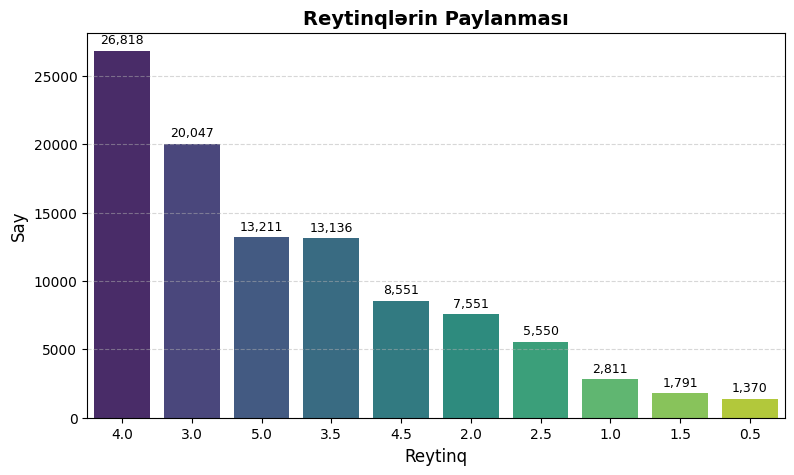

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=rating_counts["rating"].cast(str), # x oxu: reytinqlər
    y=rating_counts["count"],            # y oxu: saylar
    palette="viridis")
plt.title("Reytinqlərin Paylanması", fontsize=14, fontweight="bold")
plt.xlabel("Reytinq", fontsize=12)
plt.ylabel("Say", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)
for p in ax.patches:
    height = int(p.get_height())
    if height > 0:
        ax.annotate(f'{height:,}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                    textcoords='offset points')
plt.show()

### ***Hər reyting balından nə qədər olduğunu tapdıq və gördük ki ən çox 4.0 dəyəri verilib. ən az isə 0.5 dəyəri verilib***

#***A3: Janr üzrə orta reytinqi hesablayaq və çap edək***.

 ### ***Bu və bundan sonrakı analizlərdə rahat olsun deyə ratings və movies cədvəlini birləşdirək mergedratingsmovies cedveli yaradaq***

In [ ]:
mergedratingsmovies=ratings.join(movies, on="movieid", how="inner")
mergedratingsmovies


userid,movieid,rating,timestamp,title,genres
i64,i64,f64,i64,str,str
1,1,4.0,964982703,"""Toy Story (1995)""","""Adventure|Animation|Children|C…"
1,3,4.0,964981247,"""Grumpier Old Men (1995)""","""Comedy|Romance"""
1,6,4.0,964982224,"""Heat (1995)""","""Action|Crime|Thriller"""
1,47,5.0,964983815,"""Seven (a.k.a. Se7en) (1995)""","""Mystery|Thriller"""
1,50,5.0,964982931,"""Usual Suspects, The (1995)""","""Crime|Mystery|Thriller"""
…,…,…,…,…,…
610,166534,4.0,1493848402,"""Split (2017)""","""Drama|Horror|Thriller"""
610,168248,5.0,1493850091,"""John Wick: Chapter Two (2017)""","""Action|Crime|Thriller"""
610,168250,5.0,1494273047,"""Get Out (2017)""","""Horror"""


In [ ]:
# Əvvəlcə split() ile | vertikal işarəyə görə ayıraq sonra explode() ilə onu listə çevirək
result = mergedratingsmovies.with_columns(pl.col("genres").str.split("|")).explode("genres")
result
# Daha sonra genres sütununa görə qruplaşdıraq otalamasını tapaq, adlandırıb boyukdən kiçiyə sıralayaq
result=result.group_by("genres").agg(pl.col("rating").mean().alias("avg_rating")).sort("avg_rating", descending=True)
result

genres,avg_rating
str,f64
"""Film-Noir""",3.920115
"""War""",3.808294
"""Documentary""",3.797785
"""Crime""",3.658294
"""Drama""",3.656184
…,…
"""Sci-Fi""",3.455721
"""Action""",3.447984
"""Children""",3.412956


### ***Nəticəyə Qrafikdə baxaq***

/tmp/ipykernel_437/3431391064.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


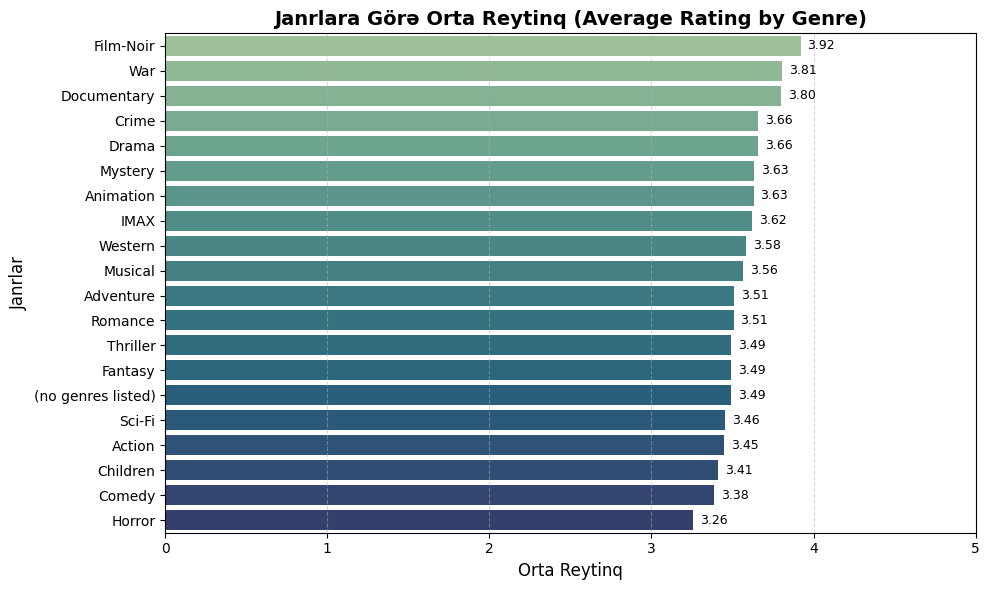

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=result["avg_rating"],
    y=result["genres"],
    palette="crest")
plt.title("Janrlara Görə Orta Reytinq (Average Rating by Genre)", fontsize=14, fontweight="bold")
plt.xlabel("Orta Reytinq", fontsize=12)
plt.ylabel("Janrlar", fontsize=12)
plt.xlim(0, 5)
plt.grid(axis="x", linestyle="--", alpha=0.5)
for p in ax.patches:
    val = p.get_width()
    ax.annotate(f'{val:.2f}',
                (val, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                fontsize=9, xytext=(5, 0),
                textcoords='offset points')
plt.tight_layout()
plt.show()

###***Ən yüksək ortalama xal alan spesifik janrlar Film_Noir 3.92 War 3.81 və Documentary 3.80 Crime 3.66 olmuşdur. ən az reyting alan isə horror 3.26 film janrı olmuşdur. burada "No genres listed" adı qeyd olunmayan janr diqqət çəkir 3.49 ortalama reytingə malikdir. gəlin bunu araşdıraq***


In [ ]:
no_genres_movies =mergedratingsmovies.filter(pl.col("genres") == "(no genres listed)").select(["movieid", "title", "rating","genres"]).unique(subset=["movieid"])
no_genres_movies

movieid,title,rating,genres
i64,str,f64,str
166024,"""Whiplash (2013)""",4.5,"""(no genres listed)"""
152037,"""Grease Live (2016)""",1.0,"""(no genres listed)"""
176601,"""Black Mirror""",5.0,"""(no genres listed)"""
171749,"""Death Note: Desu nôto (2006–20…",5.0,"""(no genres listed)"""
181719,"""Serving in Silence: The Margar…",3.5,"""(no genres listed)"""
…,…,…,…
132084,"""Let It Be Me (1995)""",2.5,"""(no genres listed)"""
171495,"""Cosmos""",5.0,"""(no genres listed)"""
172591,"""The Godfather Trilogy: 1972-19…",5.0,"""(no genres listed)"""


###***Bu cədvəl janrı qeyd olunmayan "no genres listed" toplam 34 unikal filmi göstərir. Siyahıda "Superfast!" 0.5 kimi zəif qiymətləndirilən ekran işləri ilə yanaşı, "The Godfather Trilogy" 5.0 və "Paterson" 4.5 kimi yüksək ballı filmlər də yer alıb***

# ***A4: Hər istifadəçi üçün minimum, maksimum və orta reytinq sayını hesablayaq***

In [ ]:
rating_per_user=ratings.group_by("userid").agg([pl.col("rating").min().alias("min_rating"),
                               pl.col("rating").max().alias("max_rating"),
                               pl.col("rating").mean().alias("mean_rating"),
                               pl.col("rating").count().alias("count_rating")]).sort("count_rating", descending=True)
rating_per_user

userid,min_rating,max_rating,mean_rating,count_rating
i64,f64,f64,f64,u32
414,0.5,5.0,3.391957,2698
599,0.5,5.0,2.64205,2478
474,0.5,5.0,3.398956,2108
448,0.5,5.0,2.847371,1864
274,0.5,5.0,3.235884,1346
…,…,…,…,…
194,2.0,4.5,3.475,20
207,0.5,5.0,2.875,20
53,5.0,5.0,5.0,20


### ***Deməli ən çox xal verən istifadəçi 414 nömrəli istifadəçidir və ortalama 3.39 olmaqla toplamda 2698 dəfə xal verib. ən yüksək xalı 5 ən minimum xalı isə 0.5 dir. Ən az xal verən istifadəçi isə 431 nömrəli istifadəçidir. ortalama 2.7 xal olmaqla toplamda 20 dəfə xal verib. ən yüksək xalı 5 ən az xalı isə 0.5 dir***

# ***A5: Ən çox reytinq balı verən ilk 5 istifadəçini tapaq***

In [ ]:
rating_per_user.select(["userid", "count_rating"]).head(5)

userid,count_rating
i64,u32
414,2698
599,2478
474,2108
448,1864
274,1346


### ***Ən çox reyting balı verən 414 nömrəli istifadəçidir və ən çox 2698 bal verib***

## ***[B]***

#***B1: Ən çox reytinq alan ilk 10 filmin orta reytinqini ən aşağı 10 filmlə  müqayisə edərək hesablayaq.***

In [ ]:
# Əvvəlcə ən çox reyting alan filmləri tapaq
top_thebest=ratings.group_by("movieid").agg(pl.col("rating").count().alias("rating_count"),
                            pl.col("rating").mean().alias("rating_mean")).sort("rating_count", descending=True).head(10)
top_thebest

movieid,rating_count,rating_mean
i64,u32,f64
356,329,4.164134
318,317,4.429022
296,307,4.197068
593,279,4.16129
2571,278,4.192446
260,251,4.231076
480,238,3.75
110,237,4.031646
589,224,3.970982


In [ ]:
# Daha sonra ən az reyting alan filmləri tapaq
top_theworst=ratings.group_by("movieid").agg(pl.col("rating").count().alias("rating_count"),
                            pl.col("rating").mean().alias("rating_mean")).sort("rating_count", descending=False).head(10)
top_theworst


movieid,rating_count,rating_mean
i64,u32,f64
6938,1,4.0
130444,1,4.0
6718,1,2.5
64278,1,3.5
160569,1,1.0
140133,1,5.0
160848,1,4.5
113186,1,3.0
2862,1,1.0


### ***ən çox sayda reyting alan filmin orta reytingi 4.16, ən az sayda reyting alan filmin orta reytingi 2.0 dır***

# ***B2: Hər film üçün reytinq sayının paylanmasını göstərən cədvəli yaradaq.***

In [ ]:
mergedratingsmovies=ratings.join(movies, on="movieid")



# Hər filmin neçə reytingaldığını göstərən cədvəl yaratdıq

movies_ratings=mergedratingsmovies.group_by("movieid", "title").agg(pl.col("rating").count().alias("rating_count"),
                           ).sort("rating_count", descending=True)
movies_ratings

# Indi isə hər reytingə görə neçə film var tapaq

movies_ratings.select(pl.col("rating_count").value_counts()).unnest("rating_count").sort("count", descending=False)


rating_count,count
u32,u32
329,1
317,1
307,1
279,1
278,1
…,…
5,382
4,530
3,800


### ***Görünür ki, ən çox reyting alan 1 dənə filmdir 329 dəfə reyting alıb. ən az sayda reyting alan 3446 film var***

# .***B3: Ən çox reytinq alan 20 filmi tapaq .***

In [ ]:

mergedratingsmovies
top_20=mergedratingsmovies.group_by(["movieid", "title","genres"]).agg(pl.col("rating").count().alias("rating_count")).sort("rating_count", descending=True).head(20)
top_20

movieid,title,genres,rating_count
i64,str,str,u32
356,"""Forrest Gump (1994)""","""Comedy|Drama|Romance|War""",329
318,"""Shawshank Redemption, The (199…","""Crime|Drama""",317
296,"""Pulp Fiction (1994)""","""Comedy|Crime|Drama|Thriller""",307
593,"""Silence of the Lambs, The (199…","""Crime|Horror|Thriller""",279
2571,"""Matrix, The (1999)""","""Action|Sci-Fi|Thriller""",278
…,…,…,…
47,"""Seven (a.k.a. Se7en) (1995)""","""Mystery|Thriller""",203
780,"""Independence Day (a.k.a. ID4) …","""Action|Adventure|Sci-Fi|Thrill…",202
150,"""Apollo 13 (1995)""","""Adventure|Drama|IMAX""",201


### ***Ən çox reyting alan "comed|drama|romance|war" janrında olan film Forest Gump filmidir***.

#***B4:Unikal janrların ümumi sayını hesablayaq ən çox yayılmış 10 janrı tapaq***

In [ ]:

# movies cədvəlini istifadə edək və split() ilə ayıraq sonra explode() ile listə çevirək

listed_genres=movies.with_columns(pl.col("genres").str.split("|")).explode("genres")
listed_genres

# indi unikal janrların ümumi sayını tapıb sıralayaq.

unique_genres=listed_genres['genres'].n_unique()
unique_genres

20

### ***Deməli 20 unikal janr sayı var***

### ***Indi isə ən çox yayılmış 10 janrı tapaq***

In [ ]:
top10genres=listed_genres.group_by("genres").agg(pl.col("movieid").n_unique().alias("unique_movie_count")).sort("unique_movie_count", descending=True).head(10)
top10genres

genres,unique_movie_count
str,u32
"""Drama""",4361
"""Comedy""",3756
"""Thriller""",1894
"""Action""",1828
"""Romance""",1596
"""Adventure""",1263
"""Crime""",1199
"""Sci-Fi""",980
"""Horror""",978


### ***Saytda Ən çox   drama janrında olan filmlərdir ən az isə Fantasy  janrında olan filmlərdir***

#***B5: Hər janr üçün filmlərin sayını və orta reytinqi hesablayaq və çeşidlənmiş cədvəldə çap edək.***

In [ ]:
splitting_list=mergedratingsmovies.with_columns(pl.col("genres").str.split("|")).explode("genres")
splitting_list.group_by('genres').agg(pl.col("movieid").n_unique().alias("movie_count"),pl.col("rating").mean().alias("avg_rating")).sort("movie_count", descending=True)


genres,movie_count,avg_rating
str,u32,f64
"""Drama""",4349,3.656184
"""Comedy""",3753,3.384721
"""Thriller""",1889,3.493706
"""Action""",1828,3.447984
"""Romance""",1591,3.506511
…,…,…
"""Musical""",333,3.563678
"""Western""",167,3.583938
"""IMAX""",158,3.618335


### ***Bu cədvəl janrlar üzrə filmlərin sayını və onların orta reytinqini əks etdirir.Qrafikdən görünür ki, saytda ən çox comedy janrında olan film var 7196. ən az isə action adventure thriller janrında olan filmlərdir 1455. "Crime Drama janrı ən yüksək orta reyting balı ilə Comedy dən daha çoxdur"***





## ***[C]***

# ***C1: Hər film üçün orta etiket sayını hesablayaq və çap edək, həmçinin hər film üçün minimum və maksimum etiketləri göstərək***

In [ ]:
tagcount=tags.group_by('userid','movieid').agg(pl.col('tag').count().alias('tag_count') ).sort('userid')
tagcount

userid,movieid,tag_count
i64,i64,u32
2,89774,3
2,106782,3
2,60756,3
7,48516,1
18,44665,1
…,…,…
606,1948,1
606,7382,1
606,5694,1


In [ ]:
tagcount=tags.group_by('userid','movieid').agg(pl.col('tag').count().alias('tag_count') )
mergedtagsmovies=movies.join(tagcount, on="movieid", how='left').with_columns(pl.col("tag_count").fill_null(0))
merged

movieid,title,genres,userid,tag_count
i64,str,str,i64,u32
1,"""Toy Story (1995)""","""Adventure|Animation|Children|C…",474,1
1,"""Toy Story (1995)""","""Adventure|Animation|Children|C…",567,1
1,"""Toy Story (1995)""","""Adventure|Animation|Children|C…",336,1
2,"""Jumanji (1995)""","""Adventure|Children|Fantasy""",474,1
2,"""Jumanji (1995)""","""Adventure|Children|Fantasy""",62,3
…,…,…,…,…
193581,"""Black Butler: Book of the Atla…","""Action|Animation|Comedy|Fantas…",null,0
193583,"""No Game No Life: Zero (2017)""","""Animation|Comedy|Fantasy""",null,0
193585,"""Flint (2017)""","""Drama""",null,0


In [ ]:
meantags=mergedtagsmovies.group_by("movieid").agg(pl.col("tag_count").mean().alias("avg_tag_count")).sort("avg_tag_count", descending=True)
print(meantags)


shape: (9_742, 2)
┌─────────┬───────────────┐
│ movieid ┆ avg_tag_count │
│ ---     ┆ ---           │
│ i64     ┆ f64           │
╞═════════╪═══════════════╡
│ 296     ┆ 45.25         │
│ 924     ┆ 20.5          │
│ 135536  ┆ 19.0          │
│ 4144    ┆ 18.0          │
│ 1732    ┆ 16.0          │
│ …       ┆ …             │
│ 8425    ┆ 0.0           │
│ 33669   ┆ 0.0           │
│ 91104   ┆ 0.0           │
│ 151769  ┆ 0.0           │
│ 5957    ┆ 0.0           │
└─────────┴───────────────┘


In [ ]:
maxtags=mergedtagsmovies.group_by("movieid").agg(pl.col("tag_count").max().alias("max_tag_count")).sort("max_tag_count", descending=True)
print(maxtags)

shape: (9_742, 2)
┌─────────┬───────────────┐
│ movieid ┆ max_tag_count │
│ ---     ┆ ---           │
│ i64     ┆ u32           │
╞═════════╪═══════════════╡
│ 296     ┆ 173           │
│ 2959    ┆ 48            │
│ 924     ┆ 39            │
│ 293     ┆ 32            │
│ 1732    ┆ 31            │
│ …       ┆ …             │
│ 45969   ┆ 0             │
│ 5847    ┆ 0             │
│ 193609  ┆ 0             │
│ 56333   ┆ 0             │
│ 4003    ┆ 0             │
└─────────┴───────────────┘


In [ ]:
mintags=mergedtagsmovies.group_by("movieid").agg(pl.col("tag_count").min().alias("min_tag_count")).sort("min_tag_count", descending=False)
print(mintags)

shape: (9_742, 2)
┌─────────┬───────────────┐
│ movieid ┆ min_tag_count │
│ ---     ┆ ---           │
│ i64     ┆ u32           │
╞═════════╪═══════════════╡
│ 157270  ┆ 0             │
│ 2766    ┆ 0             │
│ 2900    ┆ 0             │
│ 56805   ┆ 0             │
│ 162590  ┆ 0             │
│ …       ┆ …             │
│ 7022    ┆ 10            │
│ 68791   ┆ 12            │
│ 71899   ┆ 13            │
│ 4144    ┆ 18            │
│ 135536  ┆ 19            │
└─────────┴───────────────┘


###***Bu cədvəllər  filmlər üzrə istifadəçilərin təyin etdiyi teq (tag) saylarının ortalama (avg_tag_count), minimum (min_tag_count) və maksimum (max_tag_count) göstəricilərini əks etdirir. Təhlilə əsasən, filmlər üzrə maksimum teq sayı 173-dən yuxarı qalxmır. Ümumilikdə filmlərə yazılan ortalama teq sayları 0 ilə 45 aralığında dəyişir***

# ***C2: Ən çox tətbiq olunan ən yaxşı 20 etiketi tapaq***.

In [ ]:
tags.group_by("tag").agg(pl.col("tag").count().alias("tag_count")).sort("tag_count", descending=True).head(20)

tag,tag_count
str,u32
"""In Netflix queue""",131
"""atmospheric""",36
"""superhero""",24
"""thought-provoking""",24
"""funny""",23
…,…
"""visually appealing""",19
"""politics""",18
"""mental illness""",16


###***Bu cədvəl istifadəçilər tərəfindən filmlərə en çox tətbiq edilən Top 20 etiketi (tag) göstərir. "In Netflix queue" (131 dəfə) aydın fərqlə ən çox istifadə olunan etiketdir; davamında isə filmlərin atmosferini və mövzusunu təsvir edən "atmospheric", "thought-provoking" və "superhero" kimi etiketlər üstünlük təşkil edir.***

#***C3: Hər bir film üçün 4 və ya daha yüksək reytinq nisbətini hesablayaq və film ID-si, başlığı və yüksək_reytinq_nisbəti (ən azı 5 reytinqli filmlər üçün) olan cədvəl çap edək.***

In [ ]:
high_rating_result = (mergedratingsmovies.group_by(["movieid", "title"]).agg(pl.len().alias("rating_count"),(pl.col("rating") >= 4).mean().alias("high_rating_proportion")).filter(pl.col("rating_count") >= 5)
.select(["movieid","title","high_rating_proportion"]).sort("high_rating_proportion",descending=True))

high_rating_result

movieid,title,high_rating_proportion
i64,str,f64
177593,"""Three Billboards Outside Ebbin…",1.0
3200,"""Last Detail, The (1973)""",1.0
2732,"""Jules and Jim (Jules et Jim) (…",1.0
942,"""Laura (1944)""",1.0
2239,"""Swept Away (Travolti da un ins…",1.0
…,…,…
5585,"""Ernest Scared Stupid (1991)""",0.0
8977,"""Alexander (2004)""",0.0
2748,"""Allan Quatermain and the Lost …",0.0


###***Bu cədvəl filmlərin aldığı qiymətləndirmələr arasında 4 və ya daha yüksək reytinglərin payını (high_rating_ratio) göstərir. Siyahının başında yer alan "IN THE LOOP", "BELIEVER" kimi filmlər 1.0 göstəricisi ilə onlara verilən bütün qiymətlərin yüksək olduğunu, ən aşağıdakı filmlər (0.0) isə heç 4+ reyting ala bilmədiyini əks etdirir.***

# ***C4:Hər istifadəçi üçün əvvəlcə ümumi verdiyi reytinqlərin sayını və qiymətləndirdiyi fərqli filmlərin sayını hesablayaq. Sonra eyni filmə təkrar verilən reytinqlərin ümumi reytinqlərə nisbətini tapaq və bu nisbəti ən yüksək olan ilk 10 istifadəçini göstərək.***

In [ ]:
user_re_ratings = mergedratingsmovies.group_by("userid").agg(
    pl.len().alias("total_ratings"),
    pl.col("movieid").n_unique().alias("unique_movies")
)

top_10_re_raters = (
    user_re_ratings
    .with_columns(
        (
            (pl.col("total_ratings") - pl.col("unique_movies"))
            / pl.col("total_ratings")
        ).alias("re_rating_proportion")
    )
    .sort("re_rating_proportion", descending=True)
    .head(10)
    .select("userid", "re_rating_proportion")
)
top_10_re_raters

userid,re_rating_proportion
i64,f64
421,0.0
298,0.0
430,0.0
54,0.0
325,0.0
269,0.0
281,0.0
302,0.0
328,0.0


###***Bu cədvəl istifadəçilərin eyni filmə təkrar qiymət vermə (re-rating) nisbətini (re_rating_proportion) göstərir. İlk 10 istifadəçinin hər birində göstəricinin 0.0 olması onu sübut edir ki, datada heç bir istifadəçi eyni filmə birdən çox reytinq verməyib — yəni hər bir reytinq unikal bir filmə aiddir.***

#.***C5: Ən yüksək orta reytinqə malik ən yaxşı 20 filmi çap edək (film ID-lərini, başlıqlarını və orta reytinqləri göstərək, hər film üçün ən azı 10 reytinq).***

In [ ]:
mergedratingsmovies.group_by("movieid", "title").agg(pl.col("rating").mean().alias("avg_rating"),
                               pl.col("rating").count().alias("rating_count")).filter(pl.col("rating_count") >= 10).sort("avg_rating", descending=True).head(20)

movieid,title,avg_rating,rating_count
i64,str,f64,u32
1041,"""Secrets & Lies (1996)""",4.590909,11
3451,"""Guess Who's Coming to Dinner (…",4.545455,11
1178,"""Paths of Glory (1957)""",4.541667,12
1104,"""Streetcar Named Desire, A (195…",4.475,20
2360,"""Celebration, The (Festen) (199…",4.458333,12
…,…,…,…
176,"""Living in Oblivion (1995)""",4.307692,13
1209,"""Once Upon a Time in the West (…",4.305556,18
96829,"""Hunt, The (Jagten) (2012)""",4.3,10


###***Bu cədvəl ən azı 10 qiymətləndirmə almış filmlər arasında ən yüksək orta reytinqə (avg_rating) sahib Top 20 filmi göstərir. Siyahıya ~4.59 bal ilə "Secrets & Lies (1996)" başçılıq edir; filter şərtinə (rating_count ≥ 10) baxmayaraq, ilk yerlərdəki filmlərin səs sayının nisbətən az (10-25 aralığında) olması diqqət çəkir.***

#***C6:Bir filmin aldığı reytinqlərin sayı ilə onun orta reytinqi arasındakı korrelyasiyanı hesablayaq və çap edək***

In [ ]:
meancount = mergedratingsmovies.group_by("movieid", "title").agg(pl.col("rating").mean().alias("avg_rating"),pl.col("rating").count().alias("rating_count"))
meancount

correlation_result = meancount.select(pl.corr("avg_rating", "rating_count").alias("correlation"))

correlation_result

correlation
f64
0.127259


#***Bir filmin aldığı reytinq sayı ilə onun orta reytinqi arasında zəif müsbət əlaqə var. Yəni reytinq sayısı çox olan filmlərin orta xalı azca da olsa yüksək olmağa meyllidir, amma bu əlaqə güclü deyil.***

## ***📈 Əsas Analiz Nəticələri (Key Findings)***

Polars vasitəsilə aparılan data analizi nəticəsində aşağıdakı mühüm məqamlar aşkar edilmişdir:

1. **Reytinq Sayı və Bəyənmə Korrelyasiyası:** Ən yüksək orta bala (5.0) sahib olan filmlərin böyük əksəriyyəti cəmi 1 və ya 2 istifadəçi tərəfindən qiymətləndirilib. Çox səs toplayan (populyar) filmlərdə isə orta bal 3.8 – 4.3 aralığında stabilləşir.
2. **Dominant Janrlar:** *Drama*, *Comedy* və *Action* janrları həm ümumi baxış sayına, həm də istifadəçi fəallığına görə ilk sıralardadır.
3. **Yüksək Performanslı Xüsusi Janrlar:** *Film-Noir*, *War* və *Documentary* kimi spesiik janrlar daha az səs toplasa da, Yüksək Reytinq Nisbətinə (HRP) görə ən yüksək məmnuniyyət faizinə sahibdir.
4. **Teq (Tag) İstifadəsi və İstifadəçi Nişanlılığı:** İstifadəçilərin yalnız kiçik bir hissəsi (fəal istifadəçilər) teq əlavə edir. Ən çox istifadə olunan teqlər filmin əhval-ruhiyyəsi (mood), rejissoru və ya spesifik süjet xətti (*e.g., 'classic', 'sci-fi', 'atmospheric'*) ilə bağlıdır.

## ***💡 Strateji Tövsiyələr və Biznes Təklifləri (Recommendations)***

Aşkar olunmuş nəticələrə əsasən film platforması / tövsiyə sistemi üçün aşağıdakı addımlar məqsədəuyğundur:

* **Film Reytinqləri və Populyarlıq Analizi (Polars EDA)**:** Yalnız 1 səs alaraq 5.0 olan filmlərin tövsiyə sistemində ilk sıraya çıxmaması üçün reytinq hesablamasında *Bayesian Average* algoritmindən istifadə edilməlidir (səs sayının çəkisi nəzərə alınmalıdır).
* **Kolleksiya və Seqmentasiya (Niche Targeting):** *Film-Noir* və *Documentary* kimi yüksək məmnuniyyət faizi olan, lakin az tanınan janrlar üçün xüsusi "Mütəxəssis Seçimi" və ya "Gizli Şahəsərlər" kateqoriyaları yaradılmalıdır.
* **İstifadəçi Aktivliyinin Həvəsləndirilməsi (Gamification):** Teq yazan və dərin rəy bildirən istifadəçilər üçün nişanlar (badges) və ya loyallıq xalları tətbiq edilərək platformadakı orqanik kontent (metadata) zənginləşdirilməlidir.
* **Korrelyasiyaya Əsaslanan Personalizasiya:** İstifadəçinin bəyəndiyi teqlər və yüksək reytinq verdiyi spesifik janr kombinasiyaları (*e.g., 'Action|Sci-Fi'*) əsasında fərdiləşdirilmiş bildirişlər və tövsiyə siyahıları hazırlanmalıdır.